## fill the missing categorical value using missing string and indicator

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv('titanic_data_updated.csv')
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [7]:
X=df.drop(['PassengerId','Name','Ticket','Survived'],axis=1)
y=df['Survived']
X.head(5)

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,third,male,22.0,1,0,7.2500,NaN,S
1,first,female,38.0,1,0,71.2833,C85,C
2,third,female,26.0,0,0,7.9250,NaN,S
3,first,female,35.0,1,0,53.1000,C123,S
4,third,male,35.0,0,0,8.0500,NaN,S


In [8]:
X.isnull().sum()

Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Cabin       687
Embarked      2
dtype: int64

In [9]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


## implement missing string and inidator

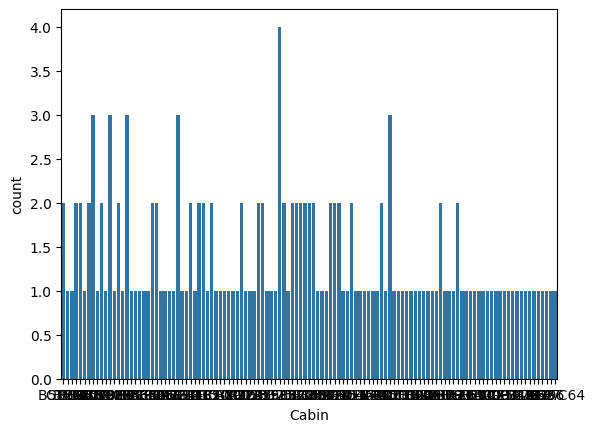

In [11]:
sns.countplot(data=X_train,x='Cabin')
plt.show()

In [13]:
missing_imputor=SimpleImputer(missing_values=np.nan,strategy='constant',add_indicator=True)
missing_imputor.fit(X_train[['Cabin']])
X_train[['Cabin','cabin_missing_indicator']]=missing_imputor.transform(X_train[['Cabin']]) # se nijei 2d data provide kore thake tai ravel use korinai
X_test[['Cabin','cabin_missing_indicator']]=missing_imputor.transform(X_test[['Cabin']])

In [14]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator
331,first,male,45.5,0,0,28.5000,C124,S,False
733,second,male,23.0,0,0,13.0000,missing_value,S,True
382,third,male,32.0,0,0,7.9250,missing_value,S,True
704,third,male,26.0,1,0,7.8542,missing_value,S,True
813,third,female,6.0,4,2,31.2750,missing_value,S,True
...,...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,missing_value,S,True
270,first,male,NaN,0,0,31.0000,missing_value,S,True
860,third,male,41.0,2,0,14.1083,missing_value,S,True
435,first,female,14.0,1,2,120.0000,B96 B98,S,False


In [15]:
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator
709,third,male,NaN,1,1,15.2458,missing_value,C,True
439,second,male,31.0,0,0,10.5000,missing_value,S,True
840,third,male,20.0,0,0,7.9250,missing_value,S,True
720,second,female,6.0,0,1,33.0000,missing_value,S,True
39,third,female,14.0,1,0,11.2417,missing_value,C,True
...,...,...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,missing_value,S,True
773,third,male,NaN,0,0,7.2250,missing_value,C,True
25,third,female,38.0,1,5,31.3875,missing_value,S,True
84,second,female,17.0,0,0,10.5000,missing_value,S,True


In [16]:
X_train.isnull().sum()

Pclass                       0
Sex                          0
Age                        140
SibSp                        0
Parch                        0
Fare                         0
Cabin                        0
Embarked                     2
cabin_missing_indicator      0
dtype: int64

In [17]:
X_test.isnull().sum()

Pclass                      0
Sex                         0
Age                        37
SibSp                       0
Parch                       0
Fare                        0
Cabin                       0
Embarked                    0
cabin_missing_indicator     0
dtype: int64